# 05a — Patient-cluster sensitivity

## Summary

Compare ordinary and patient-cluster confidence intervals on identical complete-case admissions in the refined primary and exploratory first-day-SOFA core models. The point estimate is shared; inference changes. Saved clinical execution results are displayed separately below. The default runtime remains a synthetic demonstration, not a MIMIC result.

<!-- Generated saved clinical supplement: cluster/intro; edit scripts/render_supplement_notebook_summaries.py -->

## Saved clinical results

The tables and figures in this section display saved clinical execution results from [the public aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json). They do not represent a new clinical rerun. The separately labeled execution section describes how to reproduce outputs. Any synthetic execution is explicitly labeled and is not a clinical MIMIC result.

<!-- Generated saved clinical supplement: cluster/cohort; edit scripts/render_supplement_notebook_summaries.py -->

### Admissions and patient dependence

| Measure | Count |
| --- | ---: |
| Admissions | 11,964 |
| In-hospital deaths | 1,692 |
| Patients | 9,157 |
| Patients with repeated admissions | 1,656 |
| Admissions contributed by repeat patients | 4,463 |

<!-- Generated saved clinical supplement: cluster/estimates; edit scripts/render_supplement_notebook_summaries.py -->

### Same fitted HR, different uncertainty

| Model | HR | Ordinary 95% CI | Patient-cluster 95% CI | Ordinary p | Cluster p |
| --- | ---: | --- | --- | ---: | ---: |
| Primary age/sex/era | 0.732 | 0.592–0.904 | 0.593–0.902 | 0.00383 | 0.00346 |
| Exploratory first-day SOFA core | 0.833 | 0.673–1.030 | 0.665–1.042 | 0.09122 | 0.11019 |

### Figure 1 — Ordinary and patient-cluster inference

**Data source:** Saved clinical execution results; [aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json).

![Figure 1 — Ordinary and patient-cluster inference](../assets/supplementary_cluster_forest.png)

**How to read**

- Gray circles show ordinary admission-level 95% intervals; blue squares show patient-cluster 95% intervals. Colors distinguish inference methods, not exposure groups. Each pair shares one fitted RAAS HR and the same complete cases; its vertical offset is only for readability.
- The dashed HR=1 line represents equal hazards. Patient clustering allows dependence among repeated admissions from one patient when estimating uncertainty; it does not fit a frailty model, remove confounding or change the exposure definition. A cluster interval can be wider or narrower.

**What the results show**

- The primary HR remains 0.732, with patient-cluster CI 0.593–0.902. The exploratory SOFA-core HR remains 0.833, with cluster CI 0.665–1.042, which includes 1. The core result does not establish equal hazards or equivalence.

**Interpretation limits**

- Compare uncertainty methods within a model. The two covariate specifications are not a formal between-model test or evidence of causal treatment benefit; the SOFA timing limitation remains.

## Context & Methods

Keep the current exposure, outcome, age, sex, era strata, covariates and Efron ties. Fit unpenalized Cox models and sum Efron score residuals over all admissions of each patient, including across era strata. Form an HC0 sandwich covariance with asymptotic normal Wald intervals and p-values.

### Key assumptions
- Patients are independent clusters; admissions within a patient may be dependent. This does not fit a frailty or recurrent-event process model.
- No weights, delayed entry, or finite-cluster correction are used.
- The core model retains the published first-day-SOFA timing limitation.
- Tied event/censor times are handled deterministically; synthetic coefficients and covariance are checked against R `survival::coxph`.
- Current-data execution must reproduce the ordinary saved reference before returning a result.

## Data

Run from the repository root or `notebooks/` after `uv sync --locked`. The existing bounded BigQuery loader is used only for explicit `current` mode. Pseudonymous keys stay in memory; never print source rows. Use `local` mode to inspect a previously verified aggregate run without another query.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from survival_sensitivity import run_supplement, load_local_bundle, plot_supplement
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

In [2]:
# Default is synthetic; the verified clinical rerun sets COPD_NOTEBOOK_DATA_MODE=current.
# Never display a patient-level DataFrame.
import os, json
DATA_MODE = os.environ.get("COPD_NOTEBOOK_DATA_MODE", "synthetic")  # synthetic, current, local
LOCAL_RESULT = REPO_ROOT / "reports/local_supplements/sensitivity_run02/aggregate_results.json"
BOOTSTRAP_REPLICATES = 1000 if DATA_MODE == "current" else 200

if DATA_MODE == "local":
    bundle = load_local_bundle(LOCAL_RESULT, REPO_ROOT, "cluster")
elif DATA_MODE in {"synthetic", "current"}:
    bundle = run_supplement("cluster", repo=REPO_ROOT, clinical=DATA_MODE == "current",
                            bootstrap_replicates=BOOTSTRAP_REPLICATES)
else:
    raise ValueError("Unknown DATA_MODE")
result = bundle["results"]["cluster"]
print({"data_origin": bundle["data_origin"], "supplement_version": bundle["supplement_version"],
       "main_analysis_updated": bundle["main_analysis_updated"]})
# Retain only the aggregate execution bundle under the ignored run directory.
if os.environ.get("COPD_NOTEBOOK_RUN_DIR"):
    aggregate_output = Path(os.environ["COPD_NOTEBOOK_RUN_DIR"]) / "supplement_bundle.json"
    aggregate_output.parent.mkdir(parents=True, exist_ok=True)
    aggregate_output.write_text(json.dumps(bundle, indent=2, allow_nan=False) + "\n")


{'data_origin': 'authorized_local_current_cohort', 'supplement_version': 'patient_cluster_competing_landmark_v1', 'main_analysis_updated': False}


## Runtime execution

The data-origin label above controls these execution outputs. The committed outputs were generated with current clinical data in the [verified full rerun](../docs/NOTEBOOK_EXECUTION_VALIDATION.json). A new execution defaults to synthetic inputs unless current mode is selected. Synthetic outputs validate software execution only. Figure 1 above remains the fixed published aggregate snapshot.

### Repeated admissions and ties

In [3]:
display(pd.DataFrame([{k: m[k] for k in ["n", "events", "patients", "patients_with_multiple_admissions", "admissions_from_repeat_patients", "tied_event_sets_within_era"]}
                      for m in result["models"].values()], index=list(result["models"])))

,n,events,patients,patients_with_multiple_admissions,admissions_from_repeat_patients,tied_event_sets_within_era
primary_refined,11964,1692,9157,1656,4463,1
core,11964,1692,9157,1656,4463,1


### Estimates on the same admissions

In [4]:
rows = []
for name, model in result["models"].items():
    e = model["estimates"]["raas_pre_icu"]
    rows.append({"Model": name, "Admissions": model["n"], "Patients": model["patients"],
                 "RAAS HR": e["hr"],
                 "Ordinary 95% CI": f"{e['ordinary']['lower_95']:.3f}–{e['ordinary']['upper_95']:.3f}",
                 "Cluster 95% CI": f"{e['patient_cluster']['lower_95']:.3f}–{e['patient_cluster']['upper_95']:.3f}",
                 "Ordinary p": e["ordinary"]["p"], "Cluster p": e["patient_cluster"]["p"]})
display(pd.DataFrame(rows).style.format({"RAAS HR": "{:.3f}", "Ordinary p": "{:.4g}", "Cluster p": "{:.4g}"}))

,Model,Admissions,Patients,RAAS HR,Ordinary 95% CI,Cluster 95% CI,Ordinary p,Cluster p
0,primary_refined,11964,9157,0.732,0.592–0.904,0.593–0.902,0.003832,0.003455
1,core,11964,9157,0.833,0.673–1.030,0.665–1.042,0.09122,0.1102


### Figure 2 — Ordinary and patient-cluster inference (selected execution)

**Data source:** Selected execution input; check the printed `data_origin` and plot title. Synthetic execution is a software demonstration, not a clinical MIMIC result.

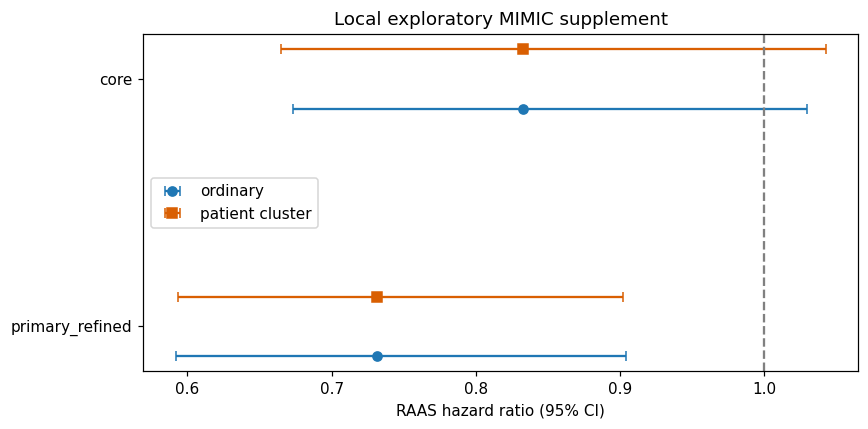

In [5]:
ANALYSIS = "cluster"
figure = plot_supplement(bundle, ANALYSIS)
display(figure)
plt.close(figure)

**How to read**

- In this runtime layout, blue circles show ordinary 95% intervals and orange squares show patient-cluster 95% intervals. These colors differ from the saved public figure's styling; in both figures the legend identifies uncertainty methods, not exposure groups.

**What the results show**

- Within each model, both markers have the same fitted HR. Their vertical separation is for visibility; changes in bar length or p-value reflect uncertainty estimation. The dashed line is HR=1. Read model row labels because the runtime layout can use a different row order.

**Interpretation limits**

- Check the title and the printed `data_origin` first. A SYNTHETIC demonstration uses artificial data and is not a clinical MIMIC finding.
- An interval including 1 does not prove no association or equivalence. Clustering addresses within-patient dependence in inference; it does not validate a causal effect or remove the first-day-SOFA timing limitation.

## Takeaways

The estimate table and forest plot compare uncertainty methods, not different fitted exposure effects. Review the primary cluster interval alongside the ordinary interval regardless of significance. Changing the published main-analysis inference requires updating its provenance and independent verification together; this notebook does not overwrite them.

See [the supplement guide](../docs/SURVIVAL_SENSITIVITY_SUPPLEMENTS.md) for the execution commands, data handling, reference checks and limitations. Tracked notebooks retain only the reviewed aggregate outputs bound in [the execution record](../docs/NOTEBOOK_EXECUTION_VALIDATION.json); full local result bundles stay under ignored `reports/local_supplements/`.